In [1]:
import pandas as pd
import glob
import os

files = glob.glob(
    "../02_UnStructured Files/Fashion MNIST/*.csv"
)

len(files), [os.path.basename(file) for file in files]

(0, [])

In [2]:
import os

os.getcwd()

'C:\\Users\\Kishan\\OneDrive\\Desktop\\DataSets\\Analysis'

In [3]:
import os

os.listdir("..")

['01_Structured Files',
 '02_UnStructered Files',
 '03_Semi Structured Files.csv',
 'Analysis',
 'STRUCTURE AND INFO']

In [4]:
import os

os.listdir("../02_UnStructered Files")

['Consumer Complaints Database', 'Fashion MNIST']

In [5]:
import os

os.listdir("../02_UnStructered Files/Fashion MNIST")

['fashion-mnist_test.csv',
 'fashion-mnist_train.csv',
 't10k-images-idx3-ubyte',
 't10k-labels-idx1-ubyte',
 'train-images-idx3-ubyte',
 'train-labels-idx1-ubyte']

In [6]:
import pandas as pd

train_df = pd.read_csv(
    "../02_UnStructered Files/Fashion MNIST/fashion-mnist_train.csv"
)

train_df.shape

(60000, 785)

In [7]:
train_df.columns

Index(['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6',
       'pixel7', 'pixel8', 'pixel9',
       ...
       'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779', 'pixel780',
       'pixel781', 'pixel782', 'pixel783', 'pixel784'],
      dtype='object', length=785)

In [8]:
train_df["label"].value_counts().sort_index()

label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64

In [9]:
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

class_names

{0: 'T-shirt/top',
 1: 'Trouser',
 2: 'Pullover',
 3: 'Dress',
 4: 'Coat',
 5: 'Sandal',
 6: 'Shirt',
 7: 'Sneaker',
 8: 'Bag',
 9: 'Ankle boot'}

In [10]:
train_df.isnull().sum().sum()

np.int64(0)

In [11]:
train_df.duplicated().sum()

np.int64(43)

In [12]:
train_clean = train_df.drop_duplicates().copy()

In [13]:
train_clean.shape

(59957, 785)

In [14]:
pixel_columns = train_clean.columns[1:]

train_clean[pixel_columns].min().min(), train_clean[pixel_columns].max().max()

(np.int64(0), np.int64(255))

In [15]:
average_pixel = train_clean[pixel_columns].mean().mean()

average_pixel

np.float64(72.95496540803222)

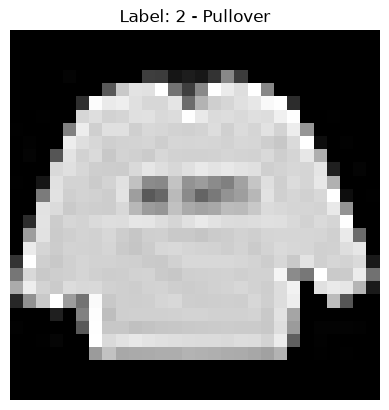

In [16]:
import matplotlib.pyplot as plt

image = train_clean.iloc[0][pixel_columns].values.reshape(28, 28)

plt.imshow(image, cmap="gray")
plt.title(
    f"Label: {train_clean.iloc[0]['label']} - "
    f"{class_names[train_clean.iloc[0]['label']]}"
)
plt.axis("off")
plt.show()

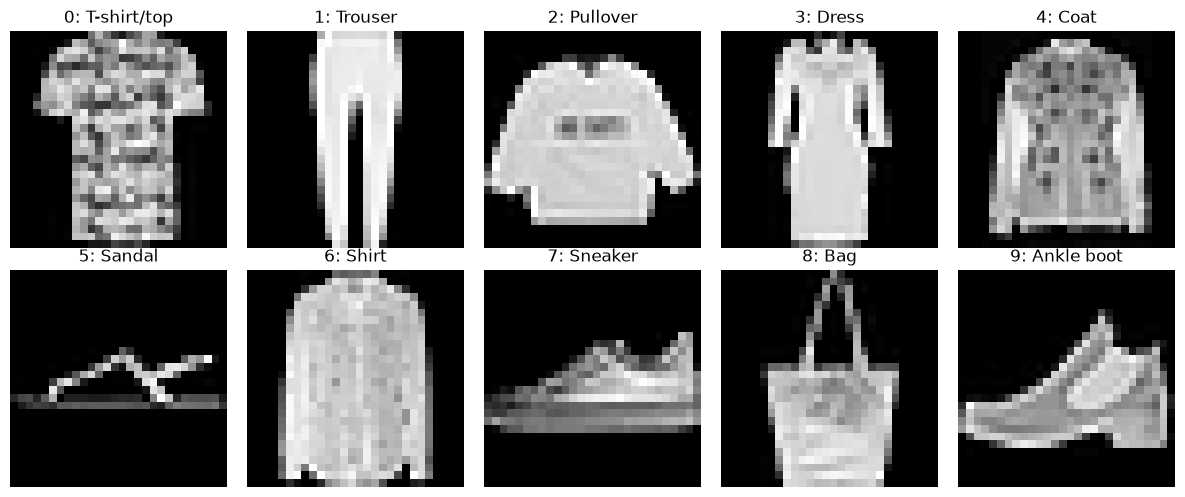

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for label, ax in enumerate(axes.flat):
    image = train_clean[train_clean["label"] == label].iloc[0][pixel_columns].values
    image = image.reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"{label}: {class_names[label]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
average_brightness = (
    train_clean
    .groupby("label")[pixel_columns]
    .mean()
    .mean(axis=1)
)

average_brightness.index = average_brightness.index.map(class_names)

average_brightness.sort_values(ascending=False)

label
Coat           98.161677
Pullover       95.727152
Bag            90.035762
Shirt          85.130134
T-shirt/top    82.887527
Ankle boot     76.998877
Dress          66.206616
Trouser        56.755050
Sneaker        42.835617
Sandal         34.870517
dtype: float64

In [19]:
class_counts = (
    train_clean["label"]
    .value_counts()
    .sort_index()
)

class_counts.index = class_counts.index.map(class_names)

class_counts

label
T-shirt/top    5998
Trouser        5996
Pullover       5988
Dress          5997
Coat           5995
Sandal         6000
Shirt          5989
Sneaker        5996
Bag            6000
Ankle boot     5998
Name: count, dtype: int64

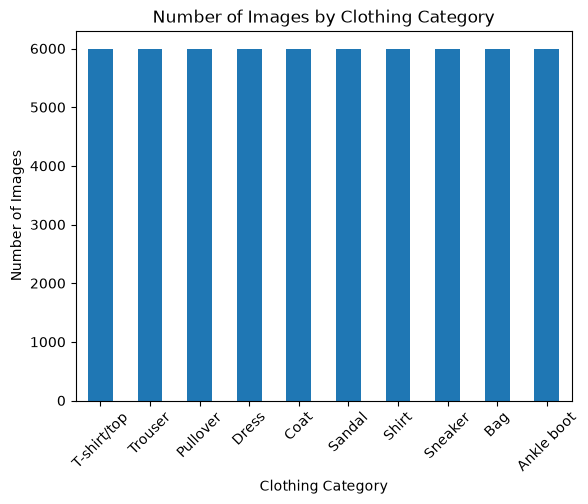

In [20]:
class_counts.plot(kind="bar")

plt.title("Number of Images by Clothing Category")
plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

In [21]:
test_df = pd.read_csv(
    "../02_UnStructered Files/Fashion MNIST/fashion-mnist_test.csv"
)

test_df.shape

(10000, 785)

In [22]:
test_df["label"].value_counts().sort_index()

label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000
Name: count, dtype: int64

In [23]:
dataset_summary = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Images": [len(train_clean), len(test_df)],
    "Classes": [train_clean["label"].nunique(), test_df["label"].nunique()]
})

dataset_summary

,Dataset,Images,Classes
0,Training,59957,10
1,Test,10000,10


In [24]:
test_missing = test_df.isnull().sum().sum()
test_duplicates = test_df.duplicated().sum()

test_missing, test_duplicates

(np.int64(0), np.int64(1))

# Fashion MNIST Analysis — Final Summary

## 1. Dataset Overview

The Fashion MNIST dataset contains grayscale images of clothing items. Each image has a size of **28 × 28 pixels**, giving a total of **784 pixel values** per image.

The CSV dataset contains:

- **1 label column**
- **784 pixel columns**
- **60,000 training images**
- **10,000 test images**
- **10 clothing categories**

After removing duplicate rows from the training dataset, the training dataset contains **59,957 unique rows**.

---

## 2. Data Structure

The dataset contains the following structure:

- `label` → clothing category
- `pixel1` to `pixel784` → grayscale pixel intensity values

Each image can be reconstructed from the 784 pixel values:

**28 × 28 = 784 pixels**

Pixel values range from **0 to 255**:

- `0` → black
- `255` → white
- Values between 0 and 255 → different shades of gray

---

## 3. Clothing Categories

The dataset contains 10 categories:

| Label | Category |
|---:|---|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

---

## 4. Data Quality Analysis

### Missing Values

The training dataset contains **0 missing values**.

The test dataset also contains **0 missing values**.

Therefore, no missing-value treatment was required.

### Duplicate Records

The original training dataset contained **43 duplicate rows**.

After removing duplicates:

- Original training rows: **60,000**
- Duplicate rows: **43**
- Cleaned training rows: **59,957**

The test dataset contained only **1 duplicate row**.

The cleaned training dataset was used for the main analysis.

---

## 5. Class Distribution

The original training dataset contains approximately **6,000 images per category**.

After duplicate removal, the distribution remained highly balanced:

| Category | Images |
|---|---:|
| T-shirt/top | 5,998 |
| Trouser | 5,996 |
| Pullover | 5,988 |
| Dress | 5,997 |
| Coat | 5,995 |
| Sandal | 6,000 |
| Shirt | 5,989 |
| Sneaker | 5,996 |
| Bag | 6,000 |
| Ankle boot | 5,998 |

The test dataset contains exactly **1,000 images for each category**.

### Key Insight

The dataset is **highly balanced**, meaning no clothing category dominates the dataset. This makes it suitable for comparative analysis and future machine-learning classification tasks.

---

## 6. Pixel Value Analysis

The minimum pixel value in the training dataset is:

**0**

The maximum pixel value is:

**255**

The overall average pixel intensity is approximately:

**72.95**

This indicates that the images are generally darker because the clothing objects are displayed against a mostly black background.

---

## 7. Average Pixel Intensity by Category

The average pixel intensity varied across clothing categories:

| Category | Average Pixel Intensity |
|---|---:|
| Coat | 98.16 |
| Pullover | 95.73 |
| Bag | 90.04 |
| Shirt | 85.13 |
| T-shirt/top | 82.89 |
| Ankle boot | 77.00 |
| Dress | 66.21 |
| Trouser | 56.76 |
| Sneaker | 42.84 |
| Sandal | 34.87 |

### Key Insight

Coats and pullovers had the highest average pixel intensity, while sandals and sneakers had the lowest.

However, pixel intensity does not represent clothing color directly. The average is also influenced by the object's size, shape, position, and the amount of black background surrounding it.

---

## 8. Image Visualization

Individual images were reconstructed from their 784 pixel values by reshaping them into a **28 × 28 matrix**.

Visualization confirmed that the numerical pixel data correctly represents clothing images.

Examples from all 10 categories were also visualized to understand the differences between clothing types.

Some categories have visually similar patterns, such as:

- T-shirt/top and Shirt
- Pullover and Coat
- Sandal, Sneaker, and Ankle boot

These similarities could make some categories more difficult to distinguish in a future image-classification model.

---

## 9. Training and Test Dataset Comparison

| Dataset | Images | Classes |
|---|---:|---:|
| Training | 59,957 after duplicate removal | 10 |
| Test | 10,000 | 10 |

The training and test datasets both contain all 10 clothing categories.

The test dataset has exactly 1,000 images per category, making it perfectly balanced.

---

## 10. Key Findings

- The Fashion MNIST dataset contains **70,000 images in total** across training and test sets.
- Each image contains **784 grayscale pixels**.
- There are **10 clothing categories**.
- The original training dataset contained **60,000 images**.
- **43 duplicate training rows** were identified and removed.
- The cleaned training dataset contains **59,957 rows**.
- There are **no missing values** in either the training or test dataset.
- The test dataset contains only **1 duplicate row**.
- Pixel values range from **0 to 255**.
- The overall average pixel intensity is approximately **72.95**.
- The dataset remains highly balanced after duplicate removal.
- Coats and pullovers have the highest average pixel intensity.
- Sandals and sneakers have the lowest average pixel intensity.
- Visual analysis shows that some clothing categories have similar shapes and pixel patterns.

---

## 11. Conclusion

The Fashion MNIST dataset was successfully loaded, cleaned, explored, and visualized using Python, Pandas, and Matplotlib.

The analysis demonstrated how image data can be represented numerically using pixel values and how those values can be analyzed using standard data-analysis techniques.

The dataset is clean, highly balanced, and contains no missing values. After removing duplicate training records, the data is suitable for further analysis and could also be used for future machine-learning classification tasks.

### Dataset Status: COMPLETE

In [26]:

import os

print("Current notebook directory:")
print(os.getcwd())

print("\nFiles and folders in the current directory:")
print(os.listdir("."))

print("\nFiles and folders one level above:")
print(os.listdir(".."))


Current notebook directory:
C:\Users\Kishan\OneDrive\Desktop\DataSets\Analysis

Files and folders in the current directory:
['.ipynb_checkpoints', '01_Amazon_Product_Reviews_Analysis.ipynb', '02_Ecommerce_Analysis.ipynb.ipynb', '03_Fashion_MNIST_Analysis.ipynb.ipynb', '04_Consumer_Complaints_Analysis.ipynb.ipynb', '05_RentTheRunway_Analysis.ipynb.ipynb', 'amazon_reviews_cleaned.csv', 'ecommerce_cleaned.csv', 'Power BI', 'SQL']

Files and folders one level above:
['01_Structured Files', '02_UnStructered Files', '03_Semi Structured Files.csv', 'Analysis', 'STRUCTURE AND INFO']


In [27]:

import os

folder_path = "../01_Structured Files"

print(os.listdir(folder_path))


['Amazon Product Reviews', 'Ecommerce Dataset (Products & Sizes Included)']


In [28]:

import os

base_path = r"C:\Users\Kishan\OneDrive\Desktop\DataSets"

for root, dirs, files in os.walk(base_path):
    for file in files:
        if "fashion" in file.lower() or "mnist" in file.lower():
            print(os.path.join(root, file))


C:\Users\Kishan\OneDrive\Desktop\DataSets\02_UnStructered Files\Fashion MNIST\fashion-mnist_test.csv
C:\Users\Kishan\OneDrive\Desktop\DataSets\02_UnStructered Files\Fashion MNIST\fashion-mnist_train.csv
C:\Users\Kishan\OneDrive\Desktop\DataSets\Analysis\03_Fashion_MNIST_Analysis.ipynb.ipynb
C:\Users\Kishan\OneDrive\Desktop\DataSets\Analysis\.ipynb_checkpoints\03_Fashion_MNIST_Analysis.ipynb-checkpoint.ipynb


In [29]:

import os
import pandas as pd

# Load the training dataset
file_path = "../02_UnStructered Files/Fashion MNIST/fashion-mnist_train.csv"

df_fashion = pd.read_csv(file_path)

# Inspect the dataset
print("Dataset shape:", df_fashion.shape)
print("\nFirst 10 column names:")
print(df_fashion.columns.tolist()[:10])

print("\nFirst five rows:")
display(df_fashion.head())

print("\nLabel distribution:")
print(df_fashion["label"].value_counts().sort_index())


Dataset shape: (60000, 785)

First 10 column names:
['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9']

First five rows:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Label distribution:
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [30]:

# 1. Check missing values
print("Total missing values:", df_fashion.isnull().sum().sum())

# 2. Check duplicate rows
print("Duplicate rows:", df_fashion.duplicated().sum())

# 3. Check label values
print("Unique labels:", sorted(df_fashion["label"].unique()))

# 4. Check pixel value range
pixel_columns = [col for col in df_fashion.columns if col.startswith("pixel")]

print("Minimum pixel value:", df_fashion[pixel_columns].min().min())
print("Maximum pixel value:", df_fashion[pixel_columns].max().max())

# 5. Check dataset memory usage
print(
    "Memory usage (MB):",
    round(df_fashion.memory_usage(deep=True).sum() / (1024 ** 2), 2)
)


Total missing values: 0
Duplicate rows: 43
Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Minimum pixel value: 0
Maximum pixel value: 255
Memory usage (MB): 359.34


In [31]:

# Create a cleaned copy of the dataset
df_fashion_clean = df_fashion.drop_duplicates().copy()

print("Original dataset shape:", df_fashion.shape)
print("Cleaned dataset shape:", df_fashion_clean.shape)
print("Duplicates remaining:", df_fashion_clean.duplicated().sum())

print("\nLabel distribution after cleaning:")
print(df_fashion_clean["label"].value_counts().sort_index())


Original dataset shape: (60000, 785)
Cleaned dataset shape: (59957, 785)
Duplicates remaining: 0

Label distribution after cleaning:
label
0    5998
1    5996
2    5988
3    5997
4    5995
5    6000
6    5989
7    5996
8    6000
9    5998
Name: count, dtype: int64


In [32]:

import os

output_path = "fashion_mnist_cleaned.csv"

df_fashion_clean.to_csv(output_path, index=False)

print("Export successful!")
print("Saved location:", os.path.abspath(output_path))
print("Rows exported:", len(df_fashion_clean))
print("Columns exported:", len(df_fashion_clean.columns))


Export successful!
Saved location: C:\Users\Kishan\OneDrive\Desktop\DataSets\Analysis\fashion_mnist_cleaned.csv
Rows exported: 59957
Columns exported: 785


In [34]:

%pip install pyodbc


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:

import pyodbc

print("Available SQL Server drivers:")
print(pyodbc.drivers())


Available SQL Server drivers:
['SQL Server', 'ODBC Driver 17 for SQL Server', 'ODBC Driver 18 for SQL Server', 'Microsoft Access Driver (*.mdb, *.accdb)', 'Microsoft Excel Driver (*.xls, *.xlsx, *.xlsm, *.xlsb)', 'Microsoft Access Text Driver (*.txt, *.csv)', 'Microsoft Access dBASE Driver (*.dbf, *.ndx, *.mdx)']


In [36]:

import pyodbc

server = r"LAPTOP-79UF7QFB\SQLEXPRESS"
database = "DataAnalyticsProject"

connection_string = (
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={server};"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
)

try:
    conn = pyodbc.connect(connection_string, timeout=10)
    cursor = conn.cursor()

    cursor.execute("SELECT DB_NAME()")
    print("Connected successfully!")
    print("Database:", cursor.fetchone()[0])

except pyodbc.Error as e:
    print("Connection failed:")
    print(e)


Connected successfully!
Database: DataAnalyticsProject


In [37]:

cursor.execute("""
SELECT TABLE_SCHEMA, TABLE_NAME
FROM INFORMATION_SCHEMA.TABLES
WHERE TABLE_NAME = 'fashion_mnist_cleaned'
""")

tables = cursor.fetchall()

if tables:
    print("Table already exists:")
    for table in tables:
        print(table.TABLE_SCHEMA, table.TABLE_NAME)
else:
    print("The fashion_mnist_cleaned table does not exist yet.")


The fashion_mnist_cleaned table does not exist yet.


In [38]:

# Create the table structure in SQL Server

column_definitions = ["image_id INT IDENTITY(1,1) PRIMARY KEY", "label INT"]

column_definitions += [
    f"pixel{i} TINYINT"
    for i in range(1, 785)
]

create_table_sql = f"""
CREATE TABLE dbo.fashion_mnist_cleaned (
    {", ".join(column_definitions)}
)
"""

cursor.execute(create_table_sql)
conn.commit()

print("Table created successfully!")
print("Table: dbo.fashion_mnist_cleaned")
print("Columns: image_id, label, and pixel1 through pixel784")


Table created successfully!
Table: dbo.fashion_mnist_cleaned
Columns: image_id, label, and pixel1 through pixel784


In [39]:

import pyodbc

# Prepare the columns and INSERT statement
data_columns = ["label"] + [f"pixel{i}" for i in range(1, 785)]

placeholders = ", ".join(["?"] * len(data_columns))
column_names = ", ".join(f"[{col}]" for col in data_columns)

insert_sql = f"""
INSERT INTO dbo.fashion_mnist_cleaned ({column_names})
VALUES ({placeholders})
"""

# Load data in batches
batch_size = 200
total_rows = len(df_fashion_clean)

cursor.fast_executemany = True

for start in range(0, total_rows, batch_size):
    batch = df_fashion_clean.iloc[start:start + batch_size]
    rows = list(batch[data_columns].itertuples(index=False, name=None))

    cursor.executemany(insert_sql, rows)
    conn.commit()

    print(f"Inserted {min(start + batch_size, total_rows):,} / {total_rows:,} rows")

print("Import completed!")


Inserted 200 / 59,957 rows
Inserted 400 / 59,957 rows
Inserted 600 / 59,957 rows
Inserted 800 / 59,957 rows
Inserted 1,000 / 59,957 rows
Inserted 1,200 / 59,957 rows
Inserted 1,400 / 59,957 rows
Inserted 1,600 / 59,957 rows
Inserted 1,800 / 59,957 rows
Inserted 2,000 / 59,957 rows
Inserted 2,200 / 59,957 rows
Inserted 2,400 / 59,957 rows
Inserted 2,600 / 59,957 rows
Inserted 2,800 / 59,957 rows
Inserted 3,000 / 59,957 rows
Inserted 3,200 / 59,957 rows
Inserted 3,400 / 59,957 rows
Inserted 3,600 / 59,957 rows
Inserted 3,800 / 59,957 rows
Inserted 4,000 / 59,957 rows
Inserted 4,200 / 59,957 rows
Inserted 4,400 / 59,957 rows
Inserted 4,600 / 59,957 rows
Inserted 4,800 / 59,957 rows
Inserted 5,000 / 59,957 rows
Inserted 5,200 / 59,957 rows
Inserted 5,400 / 59,957 rows
Inserted 5,600 / 59,957 rows
Inserted 5,800 / 59,957 rows
Inserted 6,000 / 59,957 rows
Inserted 6,200 / 59,957 rows
Inserted 6,400 / 59,957 rows
Inserted 6,600 / 59,957 rows
Inserted 6,800 / 59,957 rows
Inserted 7,000 / 59,95

In [40]:

# Verify the row count
cursor.execute("""
SELECT COUNT(*)
FROM dbo.fashion_mnist_cleaned
""")
print("Total rows in SQL Server:", cursor.fetchone()[0])

# Check the number of columns
cursor.execute("""
SELECT COUNT(*)
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_SCHEMA = 'dbo'
  AND TABLE_NAME = 'fashion_mnist_cleaned'
""")
print("Total columns in SQL Server:", cursor.fetchone()[0])

# Check image counts by label
cursor.execute("""
SELECT label, COUNT(*) AS image_count
FROM dbo.fashion_mnist_cleaned
GROUP BY label
ORDER BY label
""")

print("\nImage count by label:")
for row in cursor.fetchall():
    print(f"Label {row.label}: {row.image_count:,} images")


Total rows in SQL Server: 59957
Total columns in SQL Server: 786

Image count by label:
Label 0: 5,998 images
Label 1: 5,996 images
Label 2: 5,988 images
Label 3: 5,997 images
Label 4: 5,995 images
Label 5: 6,000 images
Label 6: 5,989 images
Label 7: 5,996 images
Label 8: 6,000 images
Label 9: 5,998 images
